In [6]:
n=19
g=1.2
mu=2.5
T=50
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from scipy.optimize import root

In [7]:
def simulate1(n,X0=-1,Nt=2000,tf=1000,g=1.0,mu=0.0,flag_display=False):
    """
    Simulation code for part 1
    Input:
        n: number of ODEs
        X0: initial condition if n-element numpy array. If X0 is an integer, the code will set 
        the initial condition (otherwise an array is expected).
        Nt: number of time steps
        tf: final time
        g,mu: model parameters
        flag_display: will generate a contour plot displaying results if True
    Output:
    t,x: numpy arrays containing times and simulation results
    """

    def model(t, X, n, g, mu):
        """
        Defines the system of ODEs 
        
        Input:
        - t: time 
        - X: array of variables [x_0, x_1, ..., x_{n-1}]
        - g, mu: scalar model parameters
        - n: number of ODEs (size of the system)
         
        Returns:
        - dXdt: array of derivatives [dx_0/dt, dx_1/dt, ..., dx_{n-1}/dt]
        """
        dXdt = np.zeros(n)
        dXdt[0] = X[0]*(1-g*X[-2]-X[0]-g*X[1]+mu*X[-3])
        dXdt[1] = X[1]*(1-g*X[-1]-X[1]-g*X[2])
        dXdt[2:n-1] = X[2:n-1]*(1-g*X[0:n-3]-X[2:n-1]-g*X[3:n])
        dXdt[-1] = X[-1]*(1-g*X[-3]-X[-1]-g*X[0])
        return dXdt

    # Parameters
    t_span = (0, tf)  # Time span for the integration
    if type(X0)==int: #(modified from original version)
        X0 = 1/(2*g+1)+0.001*np.random.rand(n)  # Random initial conditions, modify if needed

    # Solve the system
    solution = solve_ivp(
        fun=model,
        t_span=t_span,
        y0=X0,
        args=(n, g, mu),
        method='BDF',rtol=1e-10,atol=1e-10,
        t_eval=np.linspace(t_span[0], t_span[1], Nt)  # Times to evaluate the solution
    )

    t,x = solution.t,solution.y #(in original version of code this line was inside if-block below)
    if flag_display:
        # Plot the solution
        plt.contour(t,np.arange(n),x,20)
        plt.xlabel('t') #(corrected axis labels)
        plt.ylabel('i')
    return t,x

In [8]:
import numpy as np
from scipy.optimize import root


def part1q1a(n, g, mu, T):
    """Part 1, question 1 (a)
    Use the variable inputs if/as needed.
    Input:
    n: number of ODEs
    g,mu: model parameters
    T: time at which perturbation energy ratio should be maximized

    Output:
    xbar: n-element array containing non-trivial equilibrium solution
    xtilde0: n-element array corresponding to computed initial condition
    eratio: computed maximum perturbation energy ratio
    """
    xbar = np.zeros(n)
    xtilde0 = np.zeros(n)
    eratio = 0.0

    def model(X, n, g, mu):
        dXdt = np.zeros(n)
        dXdt[0] = X[0] * (1 - g * X[-2] - X[0] - g * X[1] + mu * X[-3])
        dXdt[1] = X[1] * (1 - g * X[-1] - X[1] - g * X[2])
        dXdt[2 : n - 1] = X[2 : n - 1] * (
            1 - g * X[0 : n - 3] - X[2 : n - 1] - g * X[3:n]
        )
        dXdt[-1] = X[-1] * (1 - g * X[-3] - X[-1] - g * X[0])
        return dXdt

    eventus = root(model, np.ones(n), method="krylov", args=(n, g, mu))
    x_bar = eventus.x

    B = np.zeros([n, n])
    for i in range(2, n - 1):
        B[i, i] = -1
        B[i, i - 2] = -g
        B[i, i + 1] = -g

    B[0, 0] = -1
    B[0, n - 2] = -g
    B[0, 1] = -g
    B[0, n - 3] = mu

    B[1, 1] = -1
    B[1, n - 1] = -g
    B[1, 2] = -g

    B[n - 1, n - 1] = -1
    B[n - 1, n - 3] = -g
    B[n - 1, 0] = -g

    M = np.zeros([n, n])

    for i in range(n):
        M[i, i] = 1 + np.matmul(B[i, :], x_bar)

    for i in range(n):
        for j in range(n):
            M[i, j] += B[i, j] * x_bar[i]

    eigenvalores, eigenvectores = np.linalg.eig(M)
    max_eigenvalue_index = np.argmax(np.real(eigenvalores))
    max_ratio = np.real(eigenvalores[max_eigenvalue_index])

    xbar = x_bar

    xtilde0 = eigenvectores[:, max_eigenvalue_index]

    eratio = max_ratio
    return xbar, xtilde0, eratio

Linear analysis predicted energy ratio: 1.0831
Simulation computed energy ratio: 2.5383


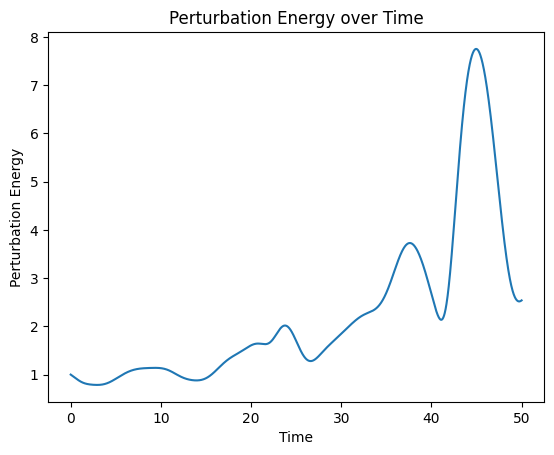

In [17]:
# Set parameters for the test
n = 19  
g = 1.2 
mu = 2.5  
T = 50  

# Results from 1q1a
xbar, xtilde0, eratio_linear = part1q1a(n, g, mu, T)

# Results from simulate1
t, x = simulate1(n=n, X0=-1, tf=T, g=g, mu=mu, flag_display=False)

perturbatio = x - xbar[:, None]  
e_t0 = np.sum(perturbatio[:, 0] ** 2)  
e_tT = np.sum(perturbatio[:, -1] ** 2)  
eratio_simulation = e_tT / e_t0  

# Compare results
print(f"Linear analysis predicted energy ratio: {eratio_linear:.4f}")
print(f"Simulation computed energy ratio: {eratio_simulation:.4f}")

# Optional: Plot perturbation energy over time
e_over_time = np.sum(perturbatio**2, axis=0)/e_t0 # Energy at each time step
plt.plot(t, e_over_time)
plt.xlabel("Time")
plt.ylabel("Perturbation Energy")
plt.title("Perturbation Energy over Time")
plt.show()

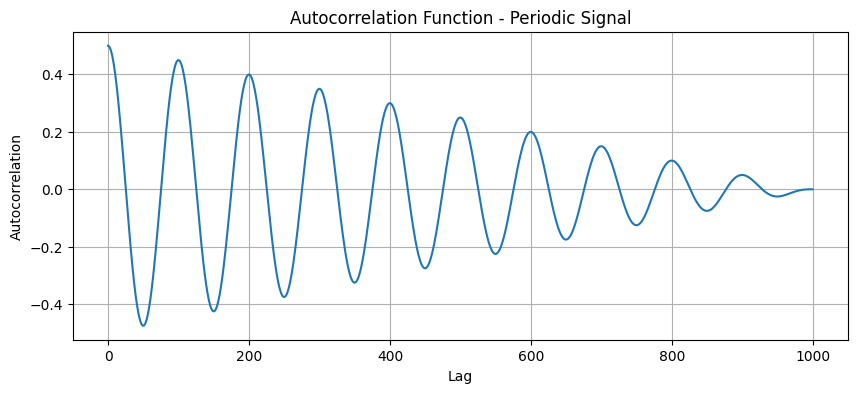

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Periodic signal: sine wave
t = np.linspace(0, 10, 1000)
signal = np.sin(2 * np.pi * 1 * t)  # Frequency = 1 Hz


# Autocorrelation function
def autocorrelation(signal):
    n = len(signal)
    mean = np.mean(signal)
    autocorr = np.correlate(signal - mean, signal - mean, mode="full") / n
    return autocorr[autocorr.size // 2 :]


autocorr = autocorrelation(signal)

# Plot
plt.figure(figsize=(10, 4))
plt.plot(autocorr)
plt.title("Autocorrelation Function - Periodic Signal")
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")
plt.grid()
plt.show()

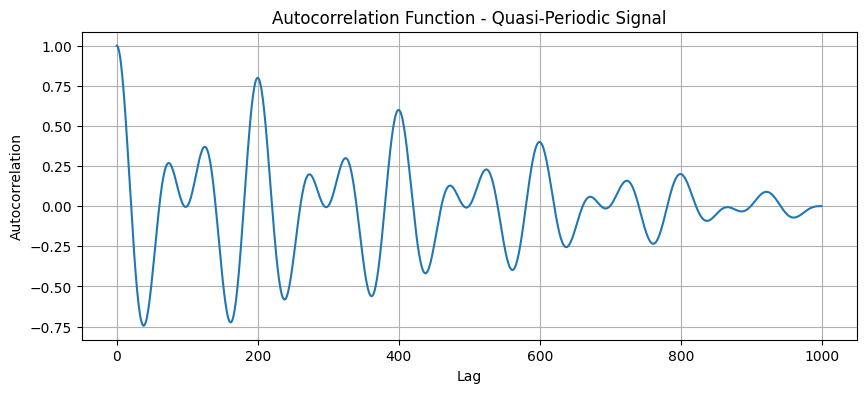

In [7]:
# Quasi-periodic signal: sum of two sine waves with incommensurate frequencies
signal = np.sin(2 * np.pi * 1 * t) + np.sin(2 * np.pi * 1.5 * t)

# Autocorrelation function
autocorr = autocorrelation(signal)

# Plot
plt.figure(figsize=(10, 4))
plt.plot(autocorr)
plt.title("Autocorrelation Function - Quasi-Periodic Signal")
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")
plt.grid()
plt.show()

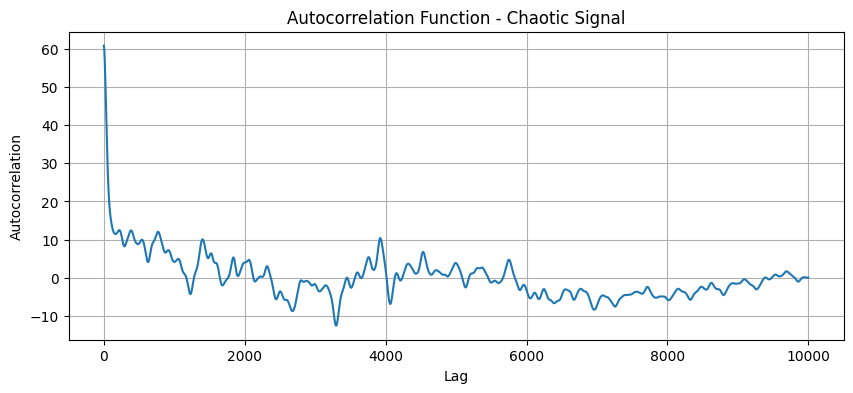

In [9]:
from scipy.integrate import solve_ivp


# Lorenz system
def lorenz_system(t, state, sigma, rho, beta):
    x, y, z = state
    dxdt = sigma * (y - x)
    dydt = x * (rho - z) - y
    dzdt = x * y - beta * z
    return [dxdt, dydt, dzdt]


# Parameters for Lorenz system
sigma, rho, beta = 10, 28, 8 / 3
initial_state = [1.0, 1.0, 1.0]
t_span = (0, 50)
t_eval = np.linspace(*t_span, 10000)

# Solve the system
solution = solve_ivp(
    lorenz_system, t_span, initial_state, t_eval=t_eval, args=(sigma, rho, beta)
)
x, y, z = solution.y

# Use one variable (e.g., x) for the signal
signal = x

# Autocorrelation function
autocorr = autocorrelation(signal)

# Plot
plt.figure(figsize=(10, 4))
plt.plot(autocorr)
plt.title("Autocorrelation Function - Chaotic Signal")
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")
plt.grid()
plt.show()

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.spatial import cKDTree


# Define the Lorenz system
def lorenz(t, state, sigma, rho, beta):
    x, y, z = state
    dxdt = sigma * (y - x)
    dydt = x * (rho - z) - y
    dzdt = x * y - beta * z
    return [dxdt, dydt, dzdt]


# Parameters for Lorenz system
sigma = 10.0
rho = 28.0
beta = 8.0 / 3.0

# Initial conditions
initial_state = [1.0, 1.0, 1.0]
t_span = (0, 50)
t_eval = np.linspace(t_span[0], t_span[1], 10000)

# Solve the Lorenz system
solution = solve_ivp(
    lorenz, t_span, initial_state, args=(sigma, rho, beta), t_eval=t_eval, method="RK45"
)

# Extract the trajectory
x, y, z = solution.y


# Function to compute the correlation sum efficiently using KD-tree
def correlation_sum_kdtree(time_series, r, m):
    N = len(time_series)
    # Create m-dimensional vectors
    vectors = np.array([time_series[i : i + m] for i in range(N - m)])

    # Build the KD-tree
    tree = cKDTree(vectors)

    # Count the number of pairs within distance r
    pairs_within_r = tree.count_neighbors(tree, r)

    # Return the normalized correlation sum
    return np.sum(pairs_within_r) / (N * (N - 1))


# Estimate the correlation dimension using a range of r values
r_values = np.logspace(-3, 1, 20)  # r values from 0.001 to 10
m = 3  # Embedding dimension
correlation_sums = [correlation_sum_kdtree(x, r, m) for r in r_values]

# Compute the correlation dimension by plotting log-log of correlation sum
plt.figure(figsize=(8, 6))
plt.plot(np.log10(r_values), np.log10(correlation_sums), marker="o")
plt.xlabel("log(r)")
plt.ylabel("log(C(r))")
plt.title("Correlation Sum for Fractal Dimension Estimation (Optimized)")
plt.grid(True)
plt.show()

# Estimating the slope (correlation dimension) from the log-log plot
# Fit the log-log data to get the slope (fractal dimension)
slope = np.polyfit(np.log10(r_values), np.log10(correlation_sums), 1)[0]
print(f"Estimated Correlation Dimension: {slope}")

KeyboardInterrupt: 

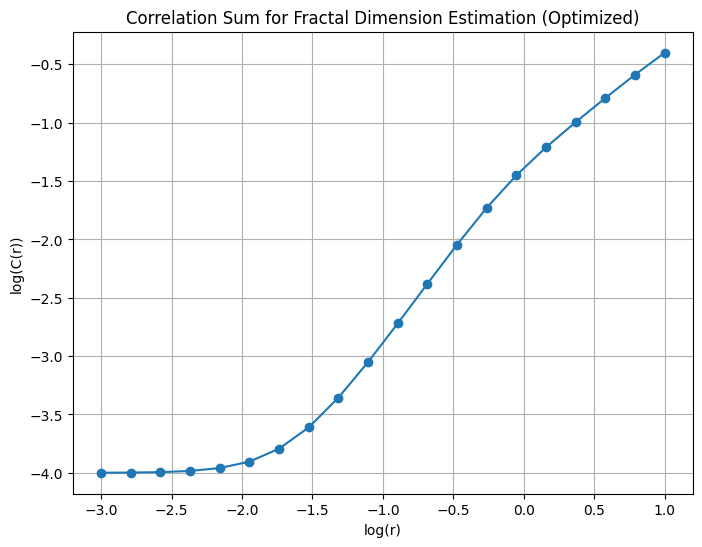

Estimated Correlation Dimension: 1.039823543392565


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.spatial import cKDTree


# Define the Lorenz system
def lorenz(t, state, sigma, rho, beta):
    x, y, z = state
    dxdt = sigma * (y - x)
    dydt = x * (rho - z) - y
    dzdt = x * y - beta * z
    return [dxdt, dydt, dzdt]


# Parameters for Lorenz system
sigma = 10.0
rho = 28.0
beta = 8.0 / 3.0

# Initial conditions
initial_state = [1.0, 1.0, 1.0]
t_span = (0, 50)
t_eval = np.linspace(t_span[0], t_span[1], 10000)

# Solve the Lorenz system
solution = solve_ivp(
    lorenz, t_span, initial_state, args=(sigma, rho, beta), t_eval=t_eval, method="RK45"
)

# Extract the trajectory
x, y, z = solution.y


# Function to compute the correlation sum efficiently using KD-tree
def correlation_sum_kdtree(time_series, r, m):
    N = len(time_series)
    # Create m-dimensional vectors
    vectors = np.array([time_series[i : i + m] for i in range(N - m)])

    # Build the KD-tree
    tree = cKDTree(vectors)

    # Count the number of pairs within distance r
    pairs_within_r = tree.count_neighbors(tree, r)

    # Return the normalized correlation sum
    return np.sum(pairs_within_r) / (N * (N - 1))


# Estimate the correlation dimension using a range of r values
r_values = np.logspace(-3, 1, 20)  # r values from 0.001 to 10
m = 3  # Embedding dimension
correlation_sums = [correlation_sum_kdtree(x, r, m) for r in r_values]

# Compute the correlation dimension by plotting log-log of correlation sum
plt.figure(figsize=(8, 6))
plt.plot(np.log10(r_values), np.log10(correlation_sums), marker="o")
plt.xlabel("log(r)")
plt.ylabel("log(C(r))")
plt.title("Correlation Sum for Fractal Dimension Estimation (Optimized)")
plt.grid(True)
plt.show()

# Estimating the slope (correlation dimension) from the log-log plot
# Fit the log-log data to get the slope (fractal dimension)
slope = np.polyfit(np.log10(r_values), np.log10(correlation_sums), 1)[0]
print(f"Estimated Correlation Dimension: {slope}")

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.spatial import cKDTree


def simulate1(n, X0=-1, Nt=2000, tf=1000, g=1.0, mu=0.0, flag_display=False):
    def model(t, X, n, g, mu):
        dXdt = np.zeros(n)
        dXdt[0] = X[0] * (1 - g * X[-2] - X[0] - g * X[1] + mu * X[-3])
        dXdt[1] = X[1] * (1 - g * X[-1] - X[1] - g * X[2])
        dXdt[2 : n - 1] = X[2 : n - 1] * (
            1 - g * X[0 : n - 3] - X[2 : n - 1] - g * X[3:n]
        )
        dXdt[-1] = X[-1] * (1 - g * X[-3] - X[-1] - g * X[0])
        return dXdt

    t_span = (0, tf)
    if type(X0) == int:
        X0 = 1 / (2 * g + 1) + 0.001 * np.random.rand(n)

    solution = solve_ivp(
        fun=model,
        t_span=t_span,
        y0=X0,
        args=(n, g, mu),
        method="BDF",
        rtol=1e-10,
        atol=1e-10,
        t_eval=np.linspace(t_span[0], t_span[1], Nt),
    )

    t, x = solution.t, solution.y
    if flag_display:
        plt.contour(t, np.arange(n), x, 20)
        plt.xlabel("t")
        plt.ylabel("i")

    return t, x


# Function to compute correlation sum using KD-tree
def correlation_sum(time_series, r, m):
    N = len(time_series)
    vectors = np.array(
        [time_series[i : i + m] for i in range(N - m)]
    )  # Create m-dimensional vectors

    # Compute pairwise distances and count pairs within distance r
    count = 0
    for i in range(len(vectors)):
        for j in range(i + 1, len(vectors)):
            distance = np.linalg.norm(vectors[i] - vectors[j])
            if distance < r:
                count += 1
    return count / (N * (N - 1))


# Function to estimate and plot the fractal dimension
def estimate_fractal_dimension(t, x, m=3):
    r_values = np.logspace(-3, 1, 20)
    correlation_sums = [
        correlation_sum(x[0], r, m) for r in r_values
    ]  # Use x[0] or any coordinate of x

    plt.figure(figsize=(8, 6))
    plt.plot(np.log10(r_values), np.log10(correlation_sums), marker="o")
    plt.xlabel("log(r)")
    plt.ylabel("log(C(r))")
    plt.title("Correlation Sum for Fractal Dimension Estimation")
    plt.grid(True)
    plt.show()

    # Estimating the slope (correlation dimension) from the log-log plot
    slope = np.polyfit(np.log10(r_values), np.log10(correlation_sums), 1)[0]
    print(f"Estimated Correlation Dimension: {slope}")


# Example usage of the simulation and fractal dimension estimation
t, X = simulate1(n=9, X0=-1, tf=1000, g=1, mu=0, flag_display=False)
t = t[900:]
X = X[:, 900:]
estimate_fractal_dimension(t, x, m=3)

KeyboardInterrupt: 

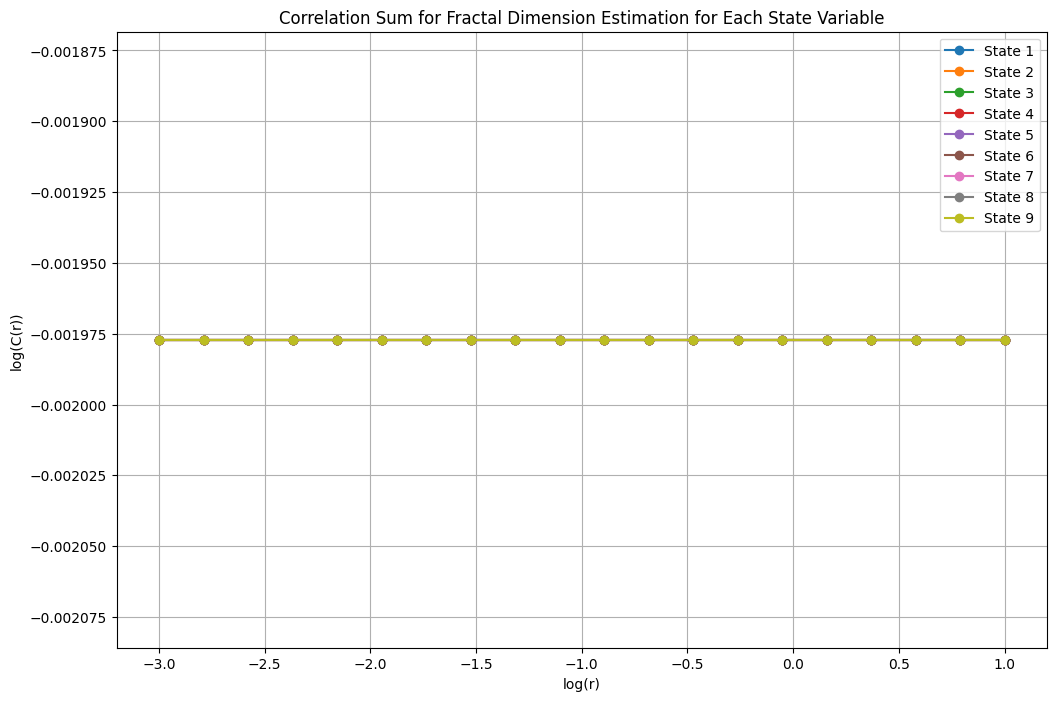

Estimated Correlation Dimension for State 1: 1.8702254384539078e-19
Estimated Correlation Dimension for State 2: 1.8702254384539078e-19
Estimated Correlation Dimension for State 3: 1.8702254384539078e-19
Estimated Correlation Dimension for State 4: 1.8702254384539078e-19
Estimated Correlation Dimension for State 5: 1.8702254384539078e-19
Estimated Correlation Dimension for State 6: 1.8702254384539078e-19
Estimated Correlation Dimension for State 7: 1.8702254384539078e-19
Estimated Correlation Dimension for State 8: 1.8702254384539078e-19
Estimated Correlation Dimension for State 9: 1.8702254384539078e-19


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.spatial.distance import cdist


def simulate1(n, X0=-1, Nt=2000, tf=1000, g=1.0, mu=0.0, flag_display=False):
    def model(t, X, n, g, mu):
        dXdt = np.zeros(n)
        dXdt[0] = X[0] * (1 - g * X[-2] - X[0] - g * X[1] + mu * X[-3])
        dXdt[1] = X[1] * (1 - g * X[-1] - X[1] - g * X[2])
        dXdt[2 : n - 1] = X[2 : n - 1] * (
            1 - g * X[0 : n - 3] - X[2 : n - 1] - g * X[3:n]
        )
        dXdt[-1] = X[-1] * (1 - g * X[-3] - X[-1] - g * X[0])
        return dXdt

    t_span = (0, tf)
    if type(X0) == int:
        X0 = 1 / (2 * g + 1) + 0.001 * np.random.rand(n)

    solution = solve_ivp(
        fun=model,
        t_span=t_span,
        y0=X0,
        args=(n, g, mu),
        method="BDF",
        rtol=1e-10,
        atol=1e-10,
        t_eval=np.linspace(t_span[0], t_span[1], Nt),
    )

    t, x = solution.t, solution.y
    if flag_display:
        plt.contour(t, np.arange(n), x, 20)
        plt.xlabel("t")
        plt.ylabel("i")

    return t, x


# Optimized function to compute the correlation sum using broadcasting and pairwise distance
def correlation_sum(time_series, r, m):
    N = len(time_series)
    vectors = np.array(
        [time_series[i : i + m] for i in range(N - m)]
    )  # Create m-dimensional vectors

    # Using scipy's cdist to compute pairwise distances more efficiently
    dist_matrix = cdist(vectors, vectors)  # Compute pairwise distances
    count = np.sum(dist_matrix < r)  # Count pairs where distance < r

    return count / (N * (N - 1))  # Normalize


# Function to estimate and plot the fractal dimension for each state variable
def estimate_fractal_dimension(t, x, m=3):
    r_values = np.logspace(-3, 1, 20)

    # Create a plot for the fractal dimension of each state variable
    plt.figure(figsize=(12, 8))
    for i in range(x.shape[0]):  # Loop over each state variable in the solution
        correlation_sums = [
            correlation_sum(x[i], r, m) for r in r_values
        ]  # Use x[i] for each state variable
        plt.plot(
            np.log10(r_values),
            np.log10(correlation_sums),
            marker="o",
            label=f"State {i+1}",
        )

    plt.xlabel("log(r)")
    plt.ylabel("log(C(r))")
    plt.title(
        "Correlation Sum for Fractal Dimension Estimation for Each State Variable"
    )
    plt.legend()
    plt.grid(True)
    plt.show()

    # Estimating the slope (correlation dimension) from the log-log plot for each state variable
    for i in range(x.shape[0]):
        correlation_sums = [correlation_sum(x[i], r, m) for r in r_values]
        slope = np.polyfit(np.log10(r_values), np.log10(correlation_sums), 1)[0]
        print(f"Estimated Correlation Dimension for State {i+1}: {slope}")


# Example usage of the simulation and fractal dimension estimation
t, X = simulate1(n=9, X0=-1, tf=1000, g=1, mu=0, flag_display=False)

# Use the last 1000 time steps for analysis (optional)
t = t[900:]
X = X[:, 900:]

# Estimate and plot the fractal dimension for each state variable
estimate_fractal_dimension(t, X, m=3)